In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
import joblib

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("spscientist/students-performance-in-exams")

print("Path to dataset files:", path)

c:\Users\cheta\Code\Personal\Data_Science\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\cheta\.cache\kagglehub\datasets\spscientist\students-performance-in-exams\versions\1


In [4]:
csv_path = f"{path}/StudentsPerformance.csv"
csv_path

'C:\\Users\\cheta\\.cache\\kagglehub\\datasets\\spscientist\\students-performance-in-exams\\versions\\1/StudentsPerformance.csv'

In [5]:
students = pd.read_csv(csv_path)

In [6]:
students

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


In [7]:
students.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


In [8]:
students.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [9]:
students['average_score'] = (students['math score'] + students['reading score'] + students['writing score']) / 3

In [10]:
students

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667
1,female,group C,some college,standard,completed,69,90,88,82.333333
2,female,group B,master's degree,standard,none,90,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333
4,male,group C,some college,standard,none,76,78,75,76.333333
...,...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95,94.000000
996,male,group C,high school,free/reduced,none,62,55,55,57.333333
997,female,group C,high school,free/reduced,completed,59,71,65,65.000000
998,female,group D,some college,standard,completed,68,78,77,74.333333


In [11]:
students["average_score"].min()

np.float64(9.0)

In [12]:
students['passed'] = (students['average_score'] >= 45)

In [13]:
students

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average_score,passed
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667,True
1,female,group C,some college,standard,completed,69,90,88,82.333333,True
2,female,group B,master's degree,standard,none,90,95,93,92.666667,True
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333,True
4,male,group C,some college,standard,none,76,78,75,76.333333,True
...,...,...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95,94.000000,True
996,male,group C,high school,free/reduced,none,62,55,55,57.333333,True
997,female,group C,high school,free/reduced,completed,59,71,65,65.000000,True
998,female,group D,some college,standard,completed,68,78,77,74.333333,True


In [14]:
students[students['passed'] == False].info()

<class 'pandas.DataFrame'>
Index: 54 entries, 7 to 988
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       54 non-null     str    
 1   race/ethnicity               54 non-null     str    
 2   parental level of education  54 non-null     str    
 3   lunch                        54 non-null     str    
 4   test preparation course      54 non-null     str    
 5   math score                   54 non-null     int64  
 6   reading score                54 non-null     int64  
 7   writing score                54 non-null     int64  
 8   average_score                54 non-null     float64
 9   passed                       54 non-null     bool   
dtypes: bool(1), float64(1), int64(3), str(5)
memory usage: 6.5 KB


In [15]:
X = students[["math score", "reading score", "writing score"]]
y = students["passed"]

In [16]:
X

,math score,reading score,writing score
0,72,72,74
1,69,90,88
2,90,95,93
3,47,57,44
4,76,78,75
...,...,...,...
995,88,99,95
996,62,55,55
997,59,71,65
998,68,78,77


In [17]:
y = y.astype(int)
y

0      1
1      1
2      1
3      1
4      1
      ..
995    1
996    1
997    1
998    1
999    1
Name: passed, Length: 1000, dtype: int64

In [18]:
from sklearn.preprocessing import StandardScaler

In [19]:
scaler = StandardScaler()

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
X_train_scaler = scaler.fit_transform(X_train)

In [23]:
X_test_scaler = scaler.transform(X_test)

In [24]:
from sklearn.linear_model import LogisticRegression

In [25]:
model = LogisticRegression()

In [26]:
model.fit(X_train_scaler, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [27]:
joblib.dump(model, "model.pkl")

['model.pkl']

In [28]:
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [29]:
prediction = model.predict(X_test_scaler)

In [30]:
predictions = X_test

In [31]:
predictions

,math score,reading score,writing score
521,91,86,84
737,53,66,73
740,80,73,72
660,74,77,73
411,84,83,78
...,...,...,...
408,52,57,56
332,62,56,53
208,74,81,76
613,65,77,74


In [32]:
predictions["predict"] = prediction

In [33]:
predictions

,math score,reading score,writing score,predict
521,91,86,84,1
737,53,66,73,1
740,80,73,72,1
660,74,77,73,1
411,84,83,78,1
...,...,...,...,...
408,52,57,56,1
332,62,56,53,1
208,74,81,76,1
613,65,77,74,1


In [34]:
predictions["actual"] = y_test

In [35]:
predictions

,math score,reading score,writing score,predict,actual
521,91,86,84,1,1
737,53,66,73,1,1
740,80,73,72,1,1
660,74,77,73,1,1
411,84,83,78,1,1
...,...,...,...,...,...
408,52,57,56,1,1
332,62,56,53,1,1
208,74,81,76,1,1
613,65,77,74,1,1


In [36]:
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report)

In [37]:
accuracy_score(y_test, prediction)

0.995

In [38]:
confusion_matrix(y_test, prediction)

array([[ 12,   1],
       [  0, 187]])

In [39]:
print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

           0       1.00      0.92      0.96        13
           1       0.99      1.00      1.00       187

    accuracy                           0.99       200
   macro avg       1.00      0.96      0.98       200
weighted avg       1.00      0.99      0.99       200



In [40]:
students.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average_score,passed
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667,True
1,female,group C,some college,standard,completed,69,90,88,82.333333,True
2,female,group B,master's degree,standard,none,90,95,93,92.666667,True
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333,True
4,male,group C,some college,standard,none,76,78,75,76.333333,True


In [41]:
students.shape

(1000, 10)

In [42]:
students.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score', 'average_score', 'passed'],
      dtype='str')

In [43]:
students.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
average_score                  0
passed                         0
dtype: int64

In [44]:
students["passed"].value_counts()

passed
True     946
False     54
Name: count, dtype: int64

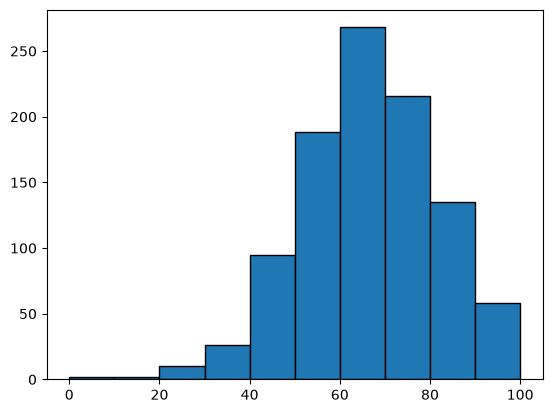

In [45]:
plt.hist(students["math score"], edgecolor="black", label="Maths_score")

plt.show()

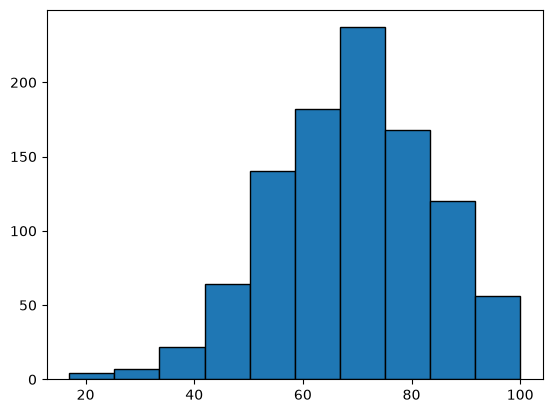

In [46]:
plt.hist(students["reading score"], edgecolor="black", label="Reading_score")

plt.show()

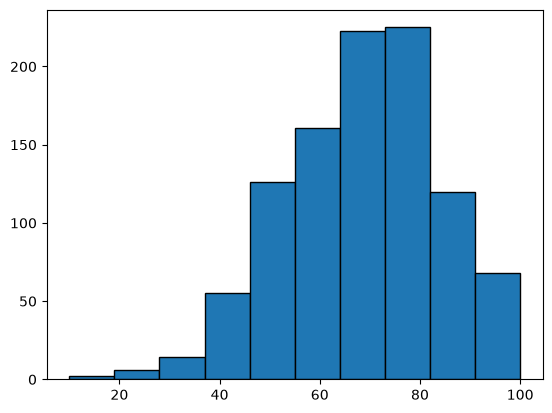

In [47]:
plt.hist(students["writing score"], edgecolor="black", label="Reading_score")

plt.show()

<BarContainer object of 1000 artists>

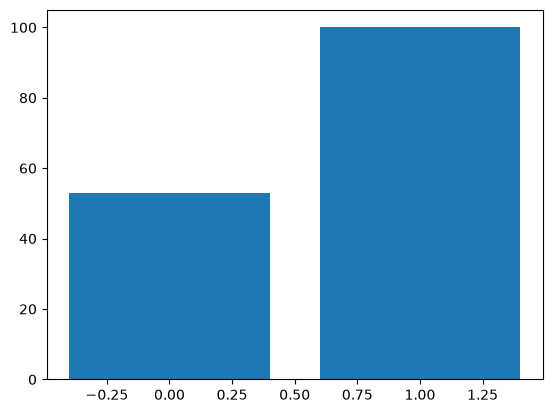

In [48]:
plt.bar(
    students["passed"],
    students["math score"]
)

In [49]:
students["passed"]

0      True
1      True
2      True
3      True
4      True
       ... 
995    True
996    True
997    True
998    True
999    True
Name: passed, Length: 1000, dtype: bool

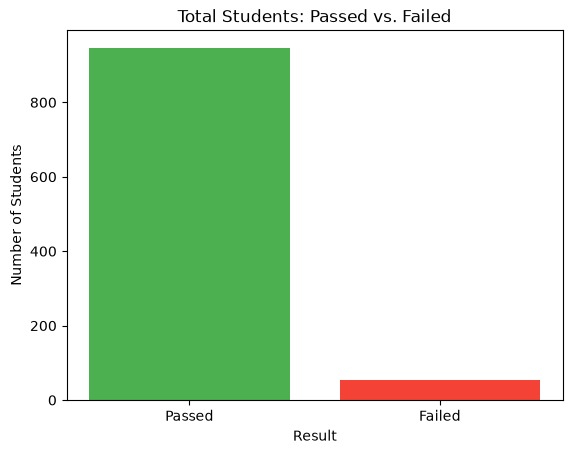

In [50]:
pass_counts = students['passed'].value_counts()

categories = ['Passed', 'Failed']
counts = [pass_counts[True], pass_counts[False]]

plt.bar(categories, counts, color=['#4CAF50', '#F44336']) 

plt.title('Total Students: Passed vs. Failed')
plt.xlabel('Result')
plt.ylabel('Number of Students')

# 5. Display the plot
plt.show()

In [51]:
counts

[np.int64(946), np.int64(54)]

In [52]:
students["passed"].unique()

array([ True, False])

In [53]:
students["passed"].unique().tolist()

[True, False]

In [54]:
students["passed"].value_counts()[True]

np.int64(946)

In [55]:
students["passed"].value_counts()[False]

np.int64(54)

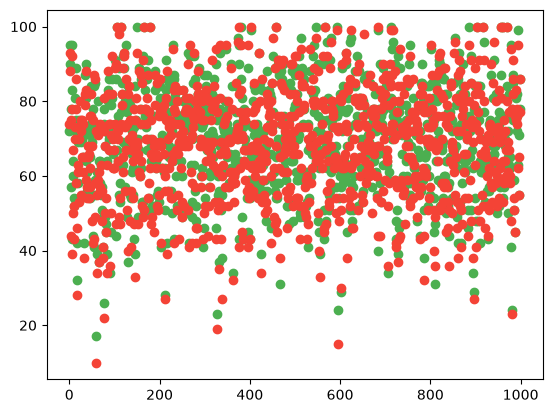

In [56]:
plt.scatter(students.index, students["reading score"], c='#4CAF50', label='Reading')

plt.scatter(students.index, students["writing score"], c='#F44336', label='Writing')

In [57]:
from sklearn.neighbors import KNeighborsClassifier

In [58]:
from sklearn.cluster import KMeans

In [59]:
inertia = []

In [60]:
X_scale = scaler.fit_transform(X)
X_scale

array([[ 0.39002351,  0.19399858,  0.39149181],
       [ 0.19207553,  1.42747598,  1.31326868],
       [ 1.57771141,  1.77010859,  1.64247471],
       ...,
       [-0.46775108,  0.12547206, -0.20107904],
       [ 0.12609287,  0.60515772,  0.58901542],
       [ 0.71993682,  1.15336989,  1.18158627]], shape=(1000, 3))

In [61]:
for k in range(1, 8):
    model_elbow = KMeans(n_clusters=k, random_state=42)

    model_elbow.fit(X_scale)
    inertia.append(model_elbow.inertia_)

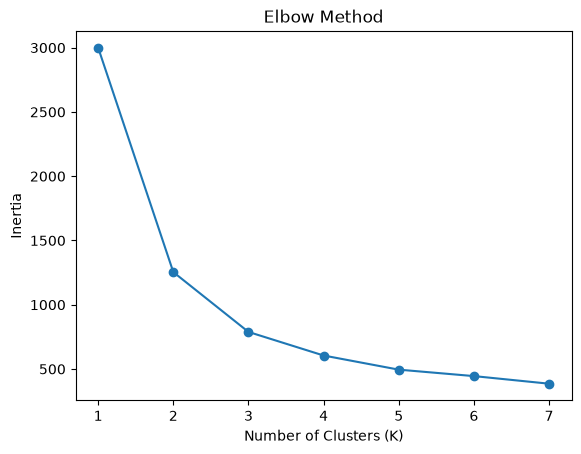

In [62]:
plt.Figure(figsize=(6,4))

plt.plot(range(1,8), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [63]:
KNN_model = KNeighborsClassifier(n_neighbors=3)

In [64]:
KNN_model.fit(X_train_scaler, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [65]:
predictions_knn = KNN_model.predict(X_test_scaler)
predictions_knn

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1])

In [66]:
prediction_knn = X_test
prediction_knn

,math score,reading score,writing score,predict,actual
521,91,86,84,1,1
737,53,66,73,1,1
740,80,73,72,1,1
660,74,77,73,1,1
411,84,83,78,1,1
...,...,...,...,...,...
408,52,57,56,1,1
332,62,56,53,1,1
208,74,81,76,1,1
613,65,77,74,1,1


In [67]:
prediction_knn["KNN_predict"] = predictions_knn

In [68]:
prediction_knn

,math score,reading score,writing score,predict,actual,KNN_predict
521,91,86,84,1,1,1
737,53,66,73,1,1,1
740,80,73,72,1,1,1
660,74,77,73,1,1,1
411,84,83,78,1,1,1
...,...,...,...,...,...,...
408,52,57,56,1,1,1
332,62,56,53,1,1,1
208,74,81,76,1,1,1
613,65,77,74,1,1,1


In [69]:
accuracy_score(predictions_knn, y_test)

0.995

In [70]:
confusion_matrix(predictions_knn, y_test)

array([[ 12,   0],
       [  1, 187]])

In [71]:
print(classification_report(predictions_knn, y_test))

              precision    recall  f1-score   support

           0       0.92      1.00      0.96        12
           1       1.00      0.99      1.00       188

    accuracy                           0.99       200
   macro avg       0.96      1.00      0.98       200
weighted avg       1.00      0.99      1.00       200

